### Imports

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from collections import Counter
from wordcloud import WordCloud

### Load dataset

In [15]:
train_data = pd.read_csv('train.txt', sep='\t', header=None, names=['title', 'from', 'genre', 'director', 'plot'])

test_data = pd.read_csv('test_no_labels.txt', sep='\t', header=None, names=['title', 'from', 'director', 'plot'])

In [16]:
genres = ['drama', 'comedy', 'horror', 'action', 'romance', 'western', 'animation', 'crime', 'sci-fi']

### Pre-processing

In [17]:
stop_words = set(stopwords.words('english')) #TODO: Maybe reduce the number of stopwords?
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r'\(\b([A-Z][a-z]*\s?)+\)', '', text)  # Remove text in brackets that starts with a capital letter (actors names)
    text = text.lower()  # Lowercase all characters
    text = re.sub(r'http\S+', '', text)  # Remove URLs #TODO: Remove this line?
    #text = re.sub(r"[^a-zA-Z+']", ' ', text)  # Keep only characters
    #text = re.sub(r'\s+[a-zA-Z]\s+', ' ', text + ' ')  # Keep words with length > 1 only
    text = "".join([i for i in text if i not in string.punctuation])
    words = word_tokenize(text)
    stopwords_ = stopwords.words('english')  # Remove stopwords
    text = " ".join([lemmatizer.lemmatize(i) for i in words if i not in stopwords_])
    text = re.sub("\s[\s]+", " ", text).strip()  # Remove repeated/leading/trailing spaces
    return text

train_data['Text_cleaning'] = train_data['plot'].apply(clean_text)
test_data['Text_cleaning'] = test_data['plot'].apply(clean_text)

train_data['Text_cleaning'].head()

0    sekhar graduate iim work business manager firm...
1    kris fowles go springwood diner meet exboyfrie...
2    cynthia traumatized death baby leaving bathtub...
3    four friend gangu abdul nihal gary form word g...
4    crisis middleclass family son fall love father...
Name: Text_cleaning, dtype: object

### Statistics

/tmp/ipykernel_36673/3180155325.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='genre' , data=train_data , order=train_data['genre'].value_counts().index, palette='viridis')


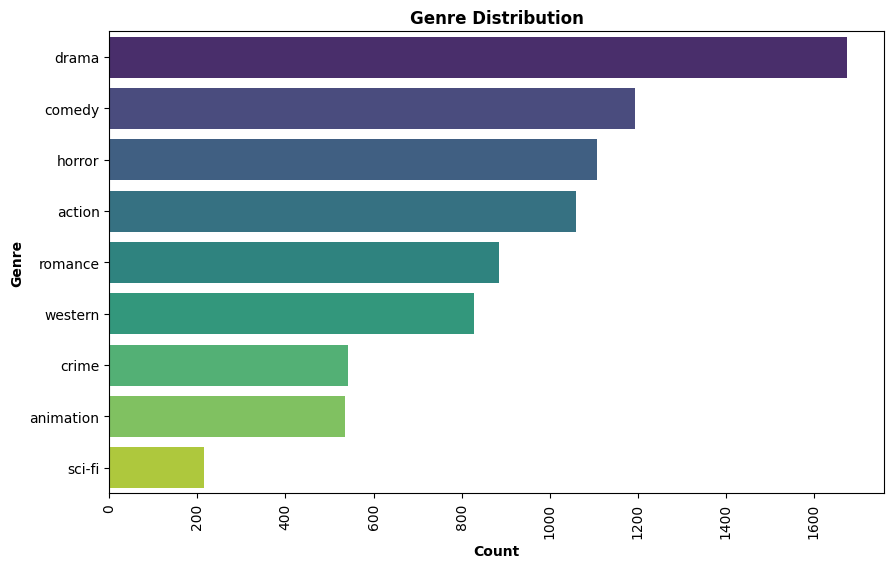

In [5]:
plt.figure(figsize=(10,6))
sns.countplot(y='genre' , data=train_data , order=train_data['genre'].value_counts().index, palette='viridis')
plt.title('Genre Distribution',fontweight='bold')
plt.xlabel('Count', fontweight='bold')
plt.ylabel('Genre', fontweight='bold')
plt.xticks(rotation=90)
plt.show()

### Frequency By Genre 

----- drama -----
[('one', 1285), ('life', 1280), ('find', 1159), ('go', 1106), ('father', 1098), ('take', 1059), ('family', 1020), ('tell', 1010), ('home', 969), ('get', 952)]
----- comedy -----
[('get', 1238), ('go', 958), ('find', 955), ('take', 855), ('friend', 821), ('one', 766), ('tell', 759), ('back', 756), ('father', 648), ('two', 624)]
----- horror -----
[('find', 2131), ('house', 1602), ('kill', 1448), ('one', 1317), ('go', 1309), ('back', 1143), ('tell', 1110), ('body', 1097), ('take', 1091), ('death', 1080)]
----- action -----
[('kill', 1436), ('police', 1105), ('get', 1077), ('one', 1059), ('take', 967), ('find', 947), ('father', 813), ('go', 806), ('killed', 762), ('escape', 703)]
----- romance -----
[('love', 1756), ('get', 1064), ('father', 925), ('friend', 835), ('go', 819), ('life', 756), ('family', 702), ('meet', 699), ('tell', 691), ('come', 682)]
----- western -----
[('town', 940), ('men', 833), ('one', 592), ('take', 579), ('back', 569), ('kill', 553), ('man', 502

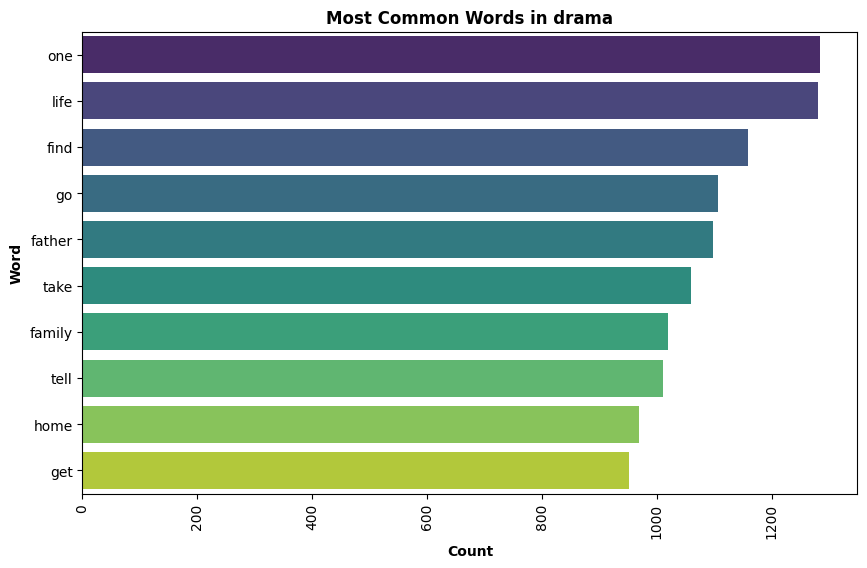

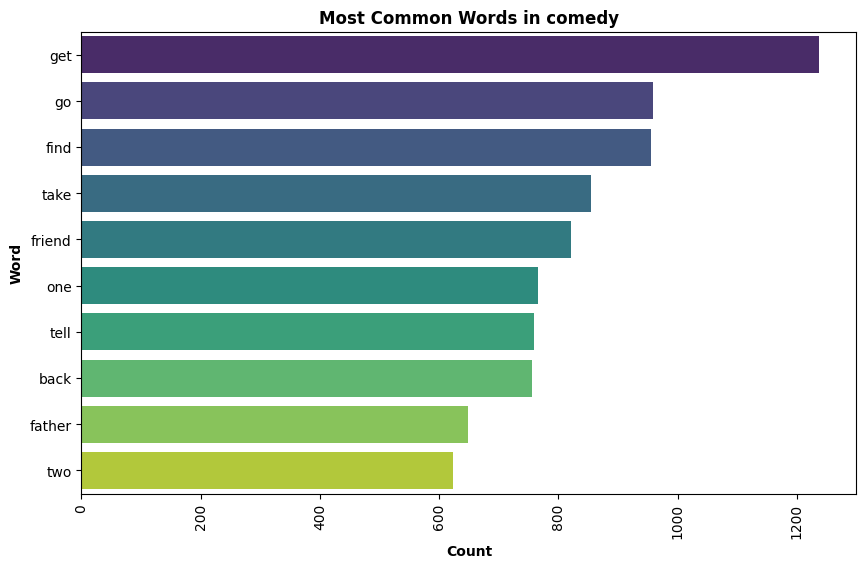

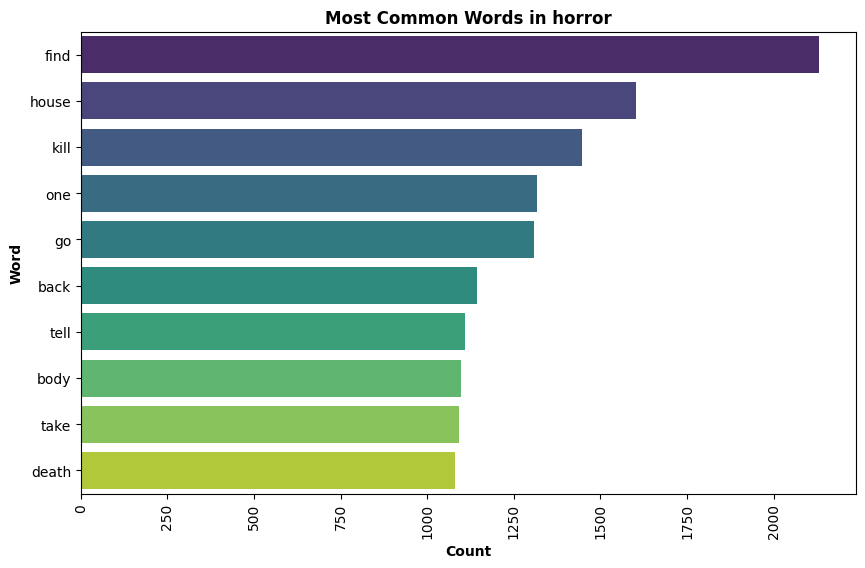

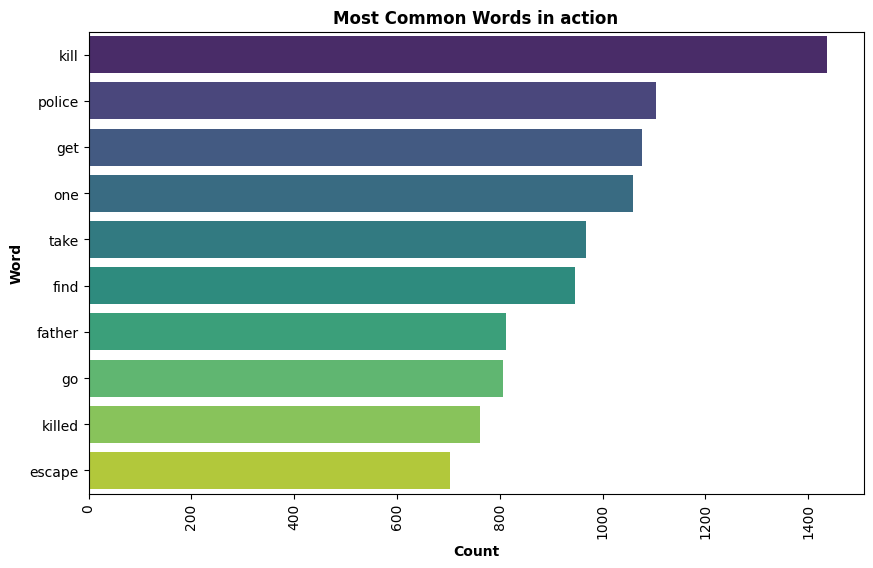

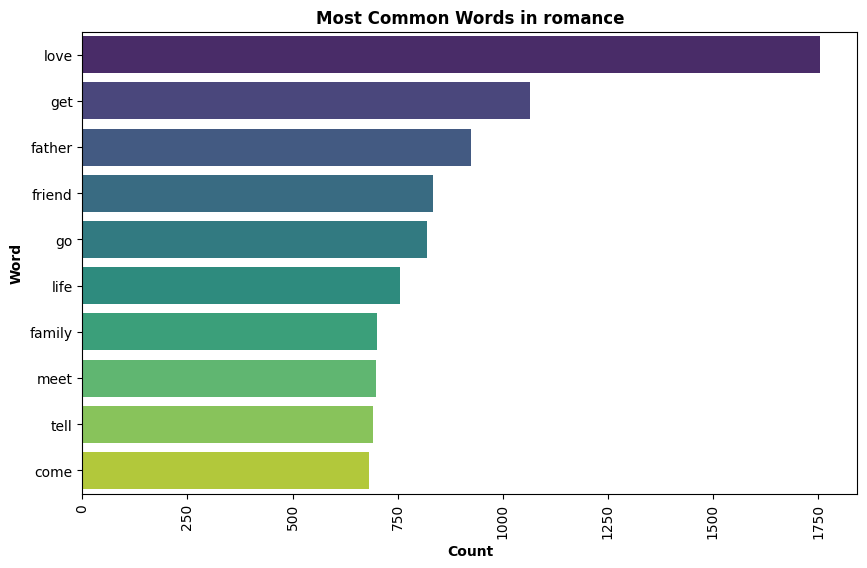

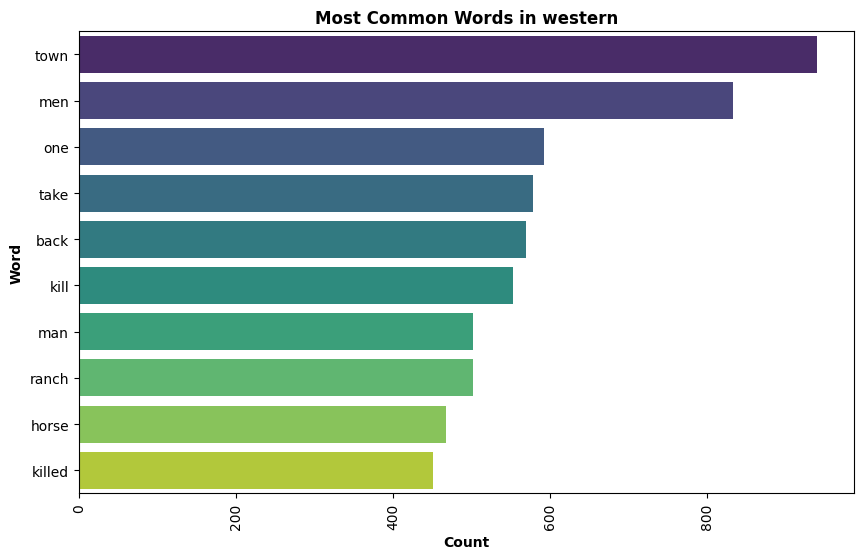

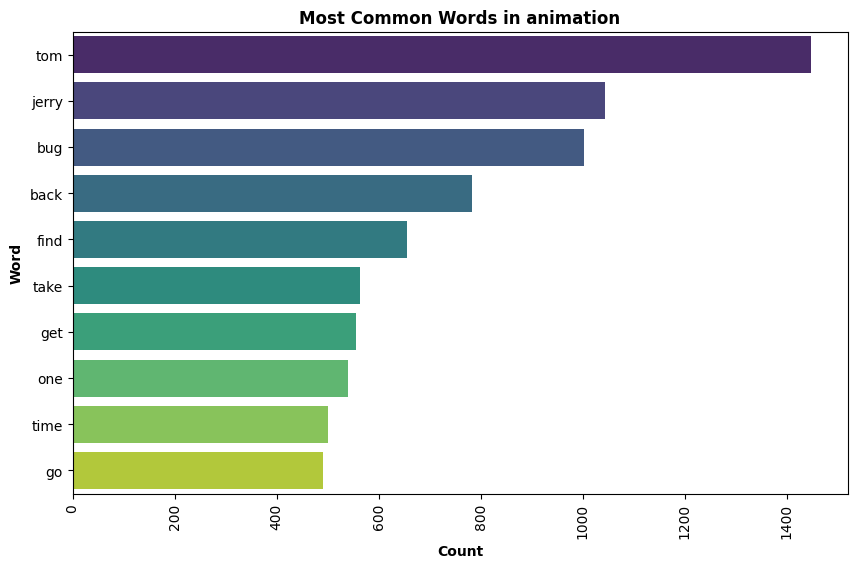

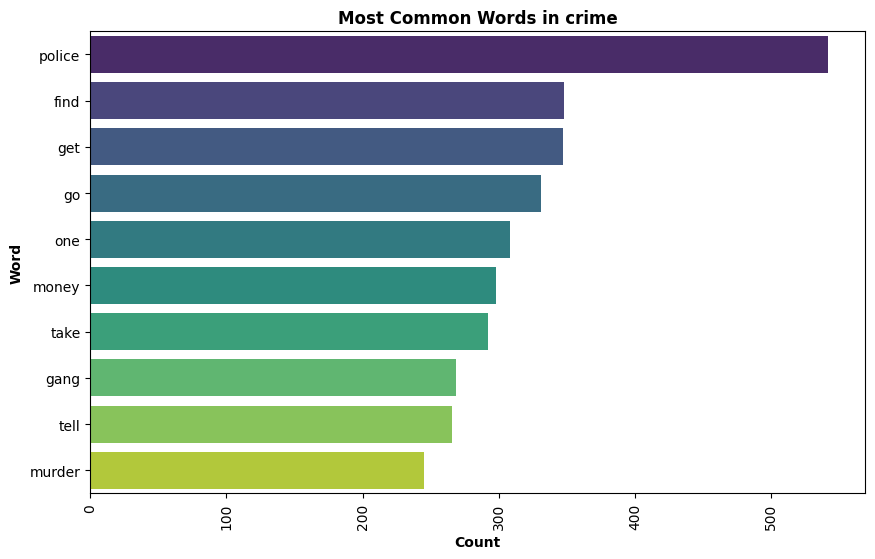

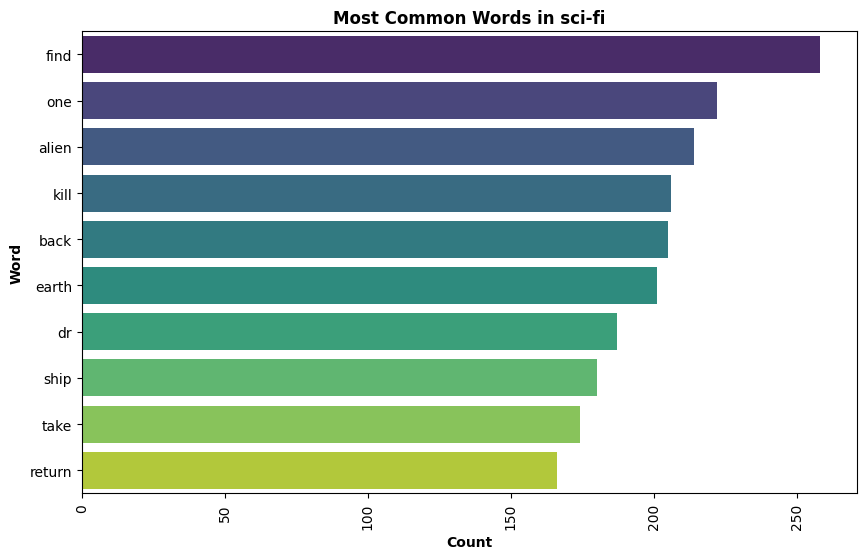

In [6]:
############# BarPlot

for genre in genres:
    
    genre_data = train_data[train_data['genre'] == genre].copy()
    genre_data['words'] = genre_data['Text_cleaning'].apply(lambda x: x.split())

    # Concatenate all tokens for the genre
    all_words = [word for tokens in genre_data['words'] for word in tokens]

    # Get the most common words
    word_counts = Counter(all_words).most_common(10)  # Top 10 most common words

    print("-----", genre, "-----")
    print(word_counts)

    # Create a DataFrame for easy plotting
    words_df = pd.DataFrame(word_counts, columns=['word', 'count'])

    # Plot for each genre
    plt.figure(figsize=(10, 6))
    sns.barplot(y='word', x='count', data=words_df, hue='word', palette='viridis', legend=False)
    plt.title(f'Most Common Words in {genre}', fontweight='bold')
    plt.xlabel('Count', fontweight='bold')
    plt.ylabel('Word', fontweight='bold')
    plt.xticks(rotation=90)
    #plt.show()

----- drama -----
[('one', 1285), ('life', 1280), ('find', 1159), ('go', 1106), ('father', 1098), ('take', 1059), ('family', 1020), ('tell', 1010), ('home', 969), ('get', 952)]
----- comedy -----
[('get', 1238), ('go', 958), ('find', 955), ('take', 855), ('friend', 821), ('one', 766), ('tell', 759), ('back', 756), ('father', 648), ('two', 624)]
----- horror -----
[('find', 2131), ('house', 1602), ('kill', 1448), ('one', 1317), ('go', 1309), ('back', 1143), ('tell', 1110), ('body', 1097), ('take', 1091), ('death', 1080)]
----- action -----
[('kill', 1436), ('police', 1105), ('get', 1077), ('one', 1059), ('take', 967), ('find', 947), ('father', 813), ('go', 806), ('killed', 762), ('escape', 703)]
----- romance -----
[('love', 1756), ('get', 1064), ('father', 925), ('friend', 835), ('go', 819), ('life', 756), ('family', 702), ('meet', 699), ('tell', 691), ('come', 682)]
----- western -----
[('town', 940), ('men', 833), ('one', 592), ('take', 579), ('back', 569), ('kill', 553), ('man', 502

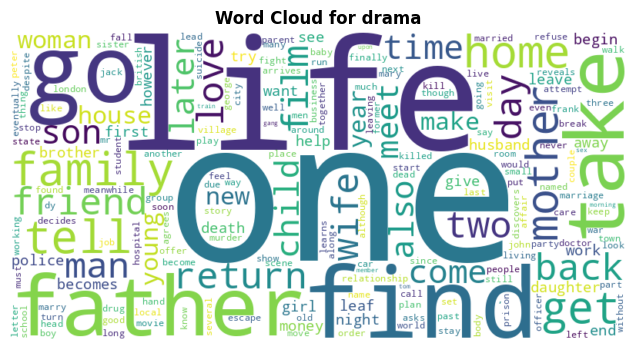

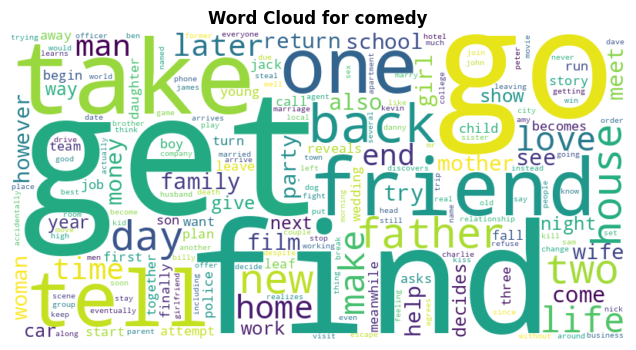

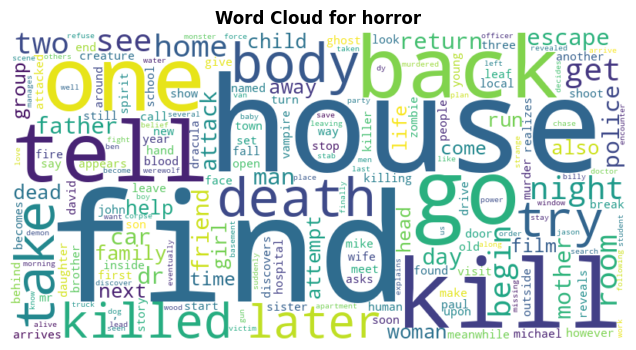

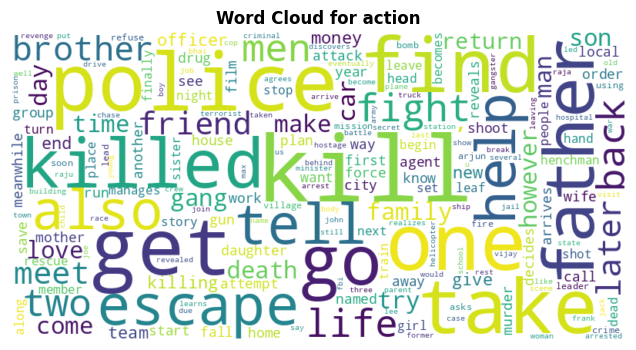

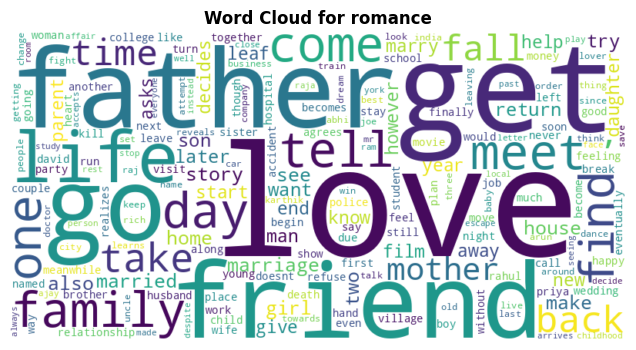

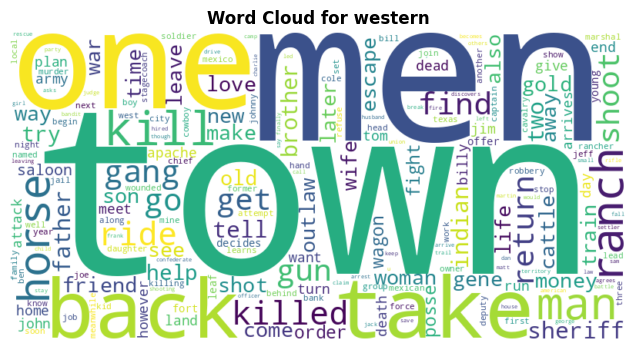

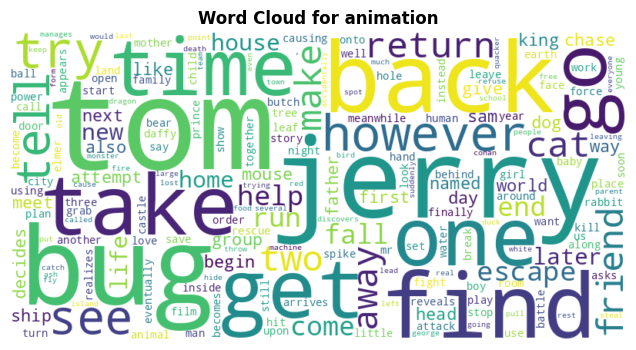

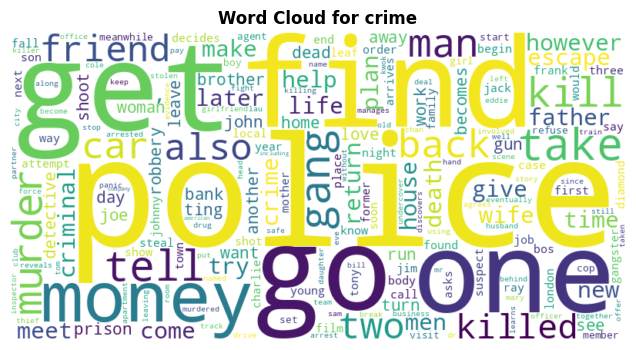

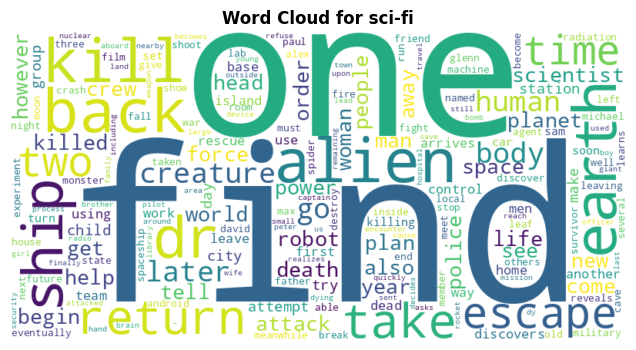

In [18]:
############# WordCloud

for genre in genres:
    genre_data = train_data[train_data['genre'] == genre].copy()
    genre_data['words'] = genre_data['Text_cleaning'].apply(lambda x: x.split())

    # Concatenate all tokens for the genre
    all_words = [word for tokens in genre_data['words'] for word in tokens]

    # Get the most common words
    word_counts = Counter(all_words)

    print("-----", genre, "-----")
    print(word_counts.most_common(10))  # You can keep this line if you still want to print the counts

    # Create a word cloud
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate_from_frequencies(word_counts)

    # Plot the word cloud
    plt.figure(figsize=(8, 4))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  # Turn off axis
    plt.title(f'Word Cloud for {genre}', fontweight='bold')
    #plt.show()  # Show the word cloud


In [ ]:
print(train_data.head())

### Training the Model

In [10]:
vectorizer = CountVectorizer()

X_train = vectorizer.fit_transform(train_data['Text_cleaning'])
X_test = vectorizer.transform(test_data['Text_cleaning'])

# Split the data into training and validation sets
X = X_train
y = train_data['genre']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train a Multinomial Naive Bayes classifier
classifier = MultinomialNB()
classifier.fit(X_train, y_train)

MultinomialNB()

### Model Validation (Train 80% - Test 20%)

In [11]:
# Make predictions on the validation set
y_pred = classifier.predict(X_val)

# Evaluate the performance of the model
accuracy = accuracy_score(y_val, y_pred)
print("Validation Accuracy:", accuracy)
print(classification_report(y_val, y_pred))

Validation Accuracy: 0.6308266003729024
              precision    recall  f1-score   support

      action       0.58      0.61      0.60       202
   animation       0.92      0.66      0.77       115
      comedy       0.55      0.46      0.50       223
       crime       0.84      0.15      0.25       108
       drama       0.49      0.67      0.57       319
      horror       0.70      0.87      0.77       223
     romance       0.57      0.57      0.57       186
      sci-fi       0.62      0.21      0.31        39
     western       0.91      0.90      0.91       194

    accuracy                           0.63      1609
   macro avg       0.69      0.57      0.58      1609
weighted avg       0.66      0.63      0.62      1609



### Model Predictions

In [ ]:
# Use the trained model to make predictions on the test data
X_test_predictions = classifier.predict(X_test)

# Save the predictions to 'results.txt' with each predicted genre in a new line
with open('results.txt', 'w') as file:
    for genre in X_test_predictions:
        file.write(genre + '\n')

print("Predictions saved to results.txt")

### Linear SVC

In [12]:
#SVC with train tes split 90/10

X = train_data['Text_cleaning']
y = train_data['genre']

##################################################################################

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=40)

##################################################################################
# Vectorize the text data using TF-IDF

vectorizer = TfidfVectorizer(analyzer='word',smooth_idf=False, stop_words=list(stop_words))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

################################################################################
# suport vector machine

svc = LinearSVC()

svc.fit(X_train_tfidf, y_train)
predictions = svc.predict(X_test_tfidf)

print("Accuracy: ",  accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

Accuracy:  0.6881987577639752
              precision    recall  f1-score   support

      action       0.60      0.59      0.59       111
   animation       0.93      0.75      0.83        73
      comedy       0.66      0.58      0.62       139
       crime       0.52      0.52      0.52        42
       drama       0.60      0.65      0.62       162
      horror       0.73      0.88      0.80       107
     romance       0.61      0.57      0.59        65
      sci-fi       0.73      0.53      0.62        15
     western       0.91      0.95      0.93        91

    accuracy                           0.69       805
   macro avg       0.70      0.67      0.68       805
weighted avg       0.69      0.69      0.69       805



In [13]:
folds = 8
train_t = vectorizer.fit_transform(train_data['Text_cleaning'])
# Cross validation
cv_predictions = cross_val_predict(svc, train_t, train_data['genre'], cv=folds)

print("WITH CROSS VALIDATION, WITH:", folds, "folds")
print("Accuracy: ", accuracy_score(train_data['genre'], cv_predictions))

WITH CROSS VALIDATION, WITH: 8 folds
Accuracy:  0.6596194503171248


In [ ]:
# Save the predictions to 'results.txt' with each predicted genre in a new line
with open('svm_results.txt', 'w') as file:
    for genre in predictions:
        file.write(genre + '\n')

print("Predictions saved to svm_results.txt")

### Logistic Regression

In [16]:
#Logistic Regression with train tes split 90/10

X = train_data['Text_cleaning']
y = train_data['genre']

##################################################################################

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

##################################################################################
# Vectorize the text data using TF-IDF

vectorizer = TfidfVectorizer(analyzer='word',smooth_idf=False, stop_words=list(stop_words)) #ngram_range=(1, 3)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

################################################################################
# Logistic Regression

log_reg = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)

log_reg.fit(X_train_tfidf, y_train)
predictions = log_reg.predict(X_test_tfidf)

print("Accuracy: ",  accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

train_t = tfidf_vectorizer.fit_transform(train_data['Text_cleaning']) #FIXME: should I use the whole data? (or may be with the movie title)

# Cross validation
cv_predictions = cross_val_predict(log_reg, train_t, train_data['genre'], cv=4)

print("Accuracy with cross validation: ", accuracy_score(train_data['genre'], cv_predictions)) 

/home/luis/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy:  0.6273291925465838
              precision    recall  f1-score   support

      action       0.63      0.60      0.61       104
   animation       0.96      0.47      0.64        57
      comedy       0.49      0.47      0.48       110
       crime       0.77      0.21      0.33        48
       drama       0.45      0.76      0.57       155
      horror       0.75      0.83      0.79       118
     romance       0.68      0.45      0.54        93
      sci-fi       0.83      0.28      0.42        18
     western       0.92      0.89      0.91       102

    accuracy                           0.63       805
   macro avg       0.72      0.55      0.59       805
weighted avg       0.67      0.63      0.62       805



/home/luis/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/luis/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/luis/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/luis/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was depr

Accuracy with cross validation:  0.6137296356174605


### Bert

In [12]:
from transformers import DistilBertForSequenceClassification
from transformers import AutoTokenizer
from transformers import Trainer, TrainingArguments
from transformers import TextDataset, DataCollatorForLanguageModeling
from tqdm import tqdm
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW 
from sklearn.preprocessing import LabelEncoder

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# Note: If you decide to encode the category labels to integers
label_encoder = LabelEncoder()
genres_as_integers = label_encoder.fit_transform(train_data['genre'])

X_train, X_val, y_train, y_val = train_test_split(train_data['plot'], genres_as_integers, test_size=0.2)

train_encodings = tokenizer(X_train.tolist(), truncation=True, padding=True)
val_encodings = tokenizer(X_val.tolist(), truncation=True, padding=True)

# Create a dataset class for the movies which inherits from PyTorch
class MovieGenreDataset(torch.utils.data.Dataset):
    def __init__(self,encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item


train_dataset = MovieGenreDataset(train_encodings, y_train)
val_dataset = MovieGenreDataset(val_encodings, y_val)

###################################################################################
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=len(genres))
model.to(device)
model.train()

#he used batch_size of 16 my pc dies :/
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)

optim = AdamW(model.parameters(), lr=5e-5)

for epoch in range(3):
    for batch in tqdm(train_loader):
        optim.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs[0]
        loss.backward()
        optim.step()
        optim.zero_grad()
model.eval()


# print accuracy on validation set

val_loader = DataLoader(val_dataset, batch_size=2, shuffle=True)

/home/luis/.local/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|███████████████████████████████████████| 3216/3216 [19:10<00:00,  2.80it/s]


### Confusion matrix

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=genres)

# Display the confusion matrix
print("Confusion Matrix:")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()

# Show the plot
plt.show()